**UNSUPERVISED LEARNING**

**Common setup**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("customer_segmentation.csv")

# Select the three features
X = df[["Age", "AnnualIncome", "SpendingScore"]]

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2D representation for plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Dataset shape:", df.shape)
display(df.head())

Saving customer_segmentation.csv to customer_segmentation.csv
Dataset shape: (500, 4)


,CustomerID,Age,AnnualIncome,SpendingScore
0,1,23,16.7,87
1,2,26,9.4,68
2,3,23,22.5,80
3,4,19,32.0,87
4,5,22,34.0,84


**K-Means clustering**

   CustomerID  KMeans
0           1       0
1           2       0
2           3       0
3           4       0
4           5       0
5           6       0
6           7       0
7           8       0
8           9       0
9          10       0

Cluster counts:
KMeans
0    100
1    107
2    101
3     88
4    104
Name: count, dtype: int64


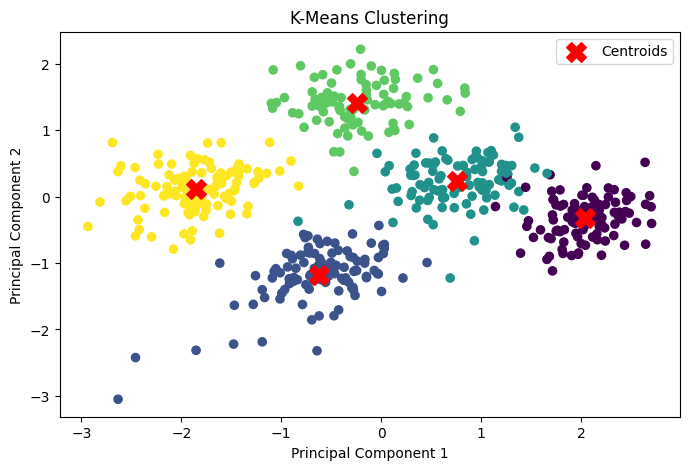

SSE: 238.521


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    init="random",
    n_init=10,
    random_state=42
)

df["KMeans"] = kmeans.fit_predict(X_scaled)

# Display cluster assignments
print(df[["CustomerID", "KMeans"]].head(10))
print("\nCluster counts:")
print(df["KMeans"].value_counts().sort_index())

# Plot clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df["KMeans"], cmap="viridis", s=35
)

centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    marker="X", s=200, c="red", label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

print("SSE:", round(kmeans.inertia_, 3))

**K-Medoids clustering**

Medoid customer IDs:
[162, 459, 326, 45, 217]

Cluster counts:
KMedoids
0    104
1     94
2    108
3    109
4     85
Name: count, dtype: int64


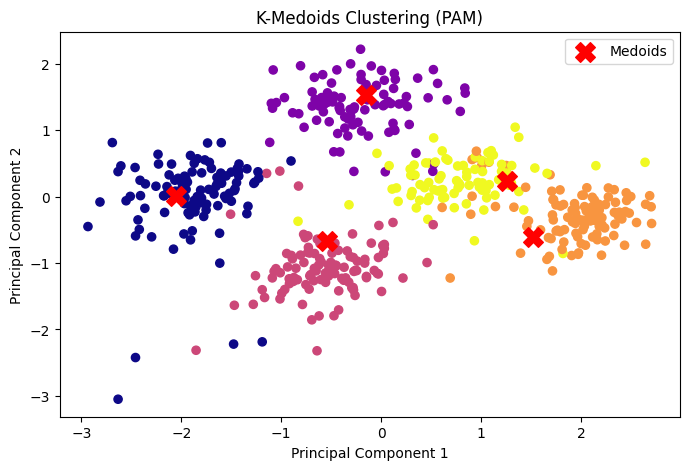

Total Manhattan distance cost: 575.192


In [ ]:
from sklearn.metrics import pairwise_distances

def k_medoids_pam(X, k=5, max_iter=20, random_state=42):
    rng = np.random.default_rng(random_state)

    # Pairwise Manhattan distances
    D = pairwise_distances(X, metric="manhattan")
    n = len(X)

    medoids = rng.choice(n, size=k, replace=False)

    def calculate_cost(selected):
        return np.min(D[:, selected], axis=1).sum()

    cost = calculate_cost(medoids)

    for iteration in range(max_iter):
        improved = False

        for i in range(k):
            for candidate in range(n):
                if candidate in medoids:
                    continue

                new_medoids = medoids.copy()
                new_medoids[i] = candidate
                new_cost = calculate_cost(new_medoids)

                if new_cost < cost:
                    medoids = new_medoids
                    cost = new_cost
                    improved = True
                    break

            if improved:
                break

        if not improved:
            break

    labels = np.argmin(D[:, medoids], axis=1)
    return labels, medoids, cost


labels, medoids, cost = k_medoids_pam(X_scaled, k=5)

df["KMedoids"] = labels

print("Medoid customer IDs:")
print(df.iloc[medoids]["CustomerID"].tolist())

print("\nCluster counts:")
print(df["KMedoids"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap="plasma", s=35
)
plt.scatter(
    X_pca[medoids, 0], X_pca[medoids, 1],
    marker="X", s=200, c="red", label="Medoids"
)
plt.title("K-Medoids Clustering (PAM)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

print("Total Manhattan distance cost:", round(cost, 3))

**Hierarchical clustering**

Cluster counts:
Hierarchical
0    104
1     63
2    111
3    122
4    100
Name: count, dtype: int64


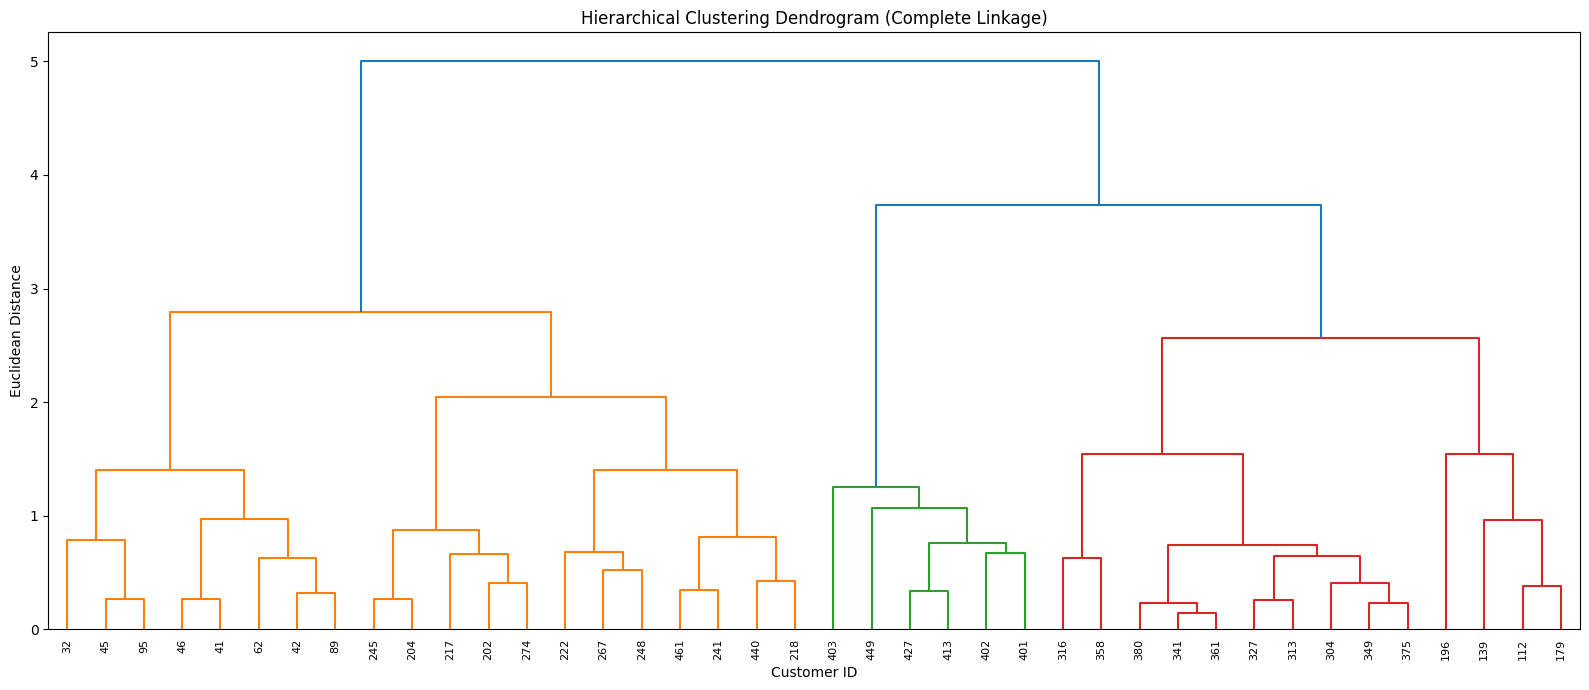

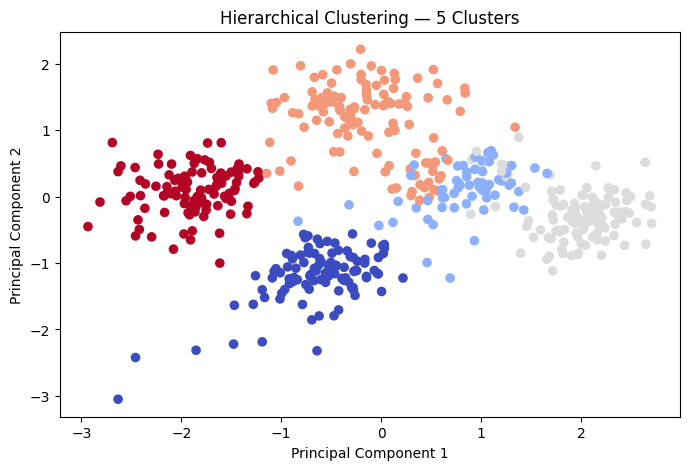

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Apply Hierarchical Clustering to all 500 records
hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage="complete",
    metric="euclidean"
)

df["Hierarchical"] = hierarchical.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Hierarchical"].value_counts().sort_index())

# 2. Draw a readable dendrogram using a 40-customer sample
sample_size = min(40, len(X_scaled))
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)

X_sample = X_scaled[sample_indices]

# Complete-linkage hierarchy
Z = linkage(X_sample, method="complete", metric="euclidean")

plt.figure(figsize=(16, 7))
dendrogram(
    Z,
    labels=df.iloc[sample_indices]["CustomerID"].astype(str).values,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Hierarchical Clustering Dendrogram (Complete Linkage)")
plt.xlabel("Customer ID")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

# 3. Visualize cluster labels for all records
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df["Hierarchical"], cmap="coolwarm", s=35
)
plt.title("Hierarchical Clustering — 5 Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

**DBSCAN clustering**

Cluster counts:
DBSCAN
-1     12
 0    488
Name: count, dtype: int64

Noise points: 12


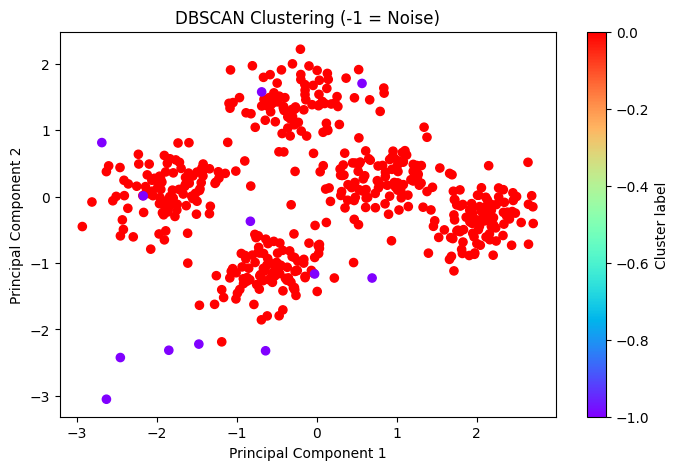

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.65,
    min_samples=8,
    metric="euclidean"
)

df["DBSCAN"] = dbscan.fit_predict(X_scaled)

print("Cluster counts:")
print(df["DBSCAN"].value_counts().sort_index())

# Noise points have label -1
noise_count = (df["DBSCAN"] == -1).sum()
print("\nNoise points:", noise_count)

# Plot clusters and noise
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df["DBSCAN"], cmap="rainbow", s=35
)
plt.title("DBSCAN Clustering (-1 = Noise)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster label")
plt.show()

**Comparation**

In [ ]:
from sklearn.metrics import silhouette_score

cluster_columns = {
    "K-Means": "KMeans",
    "K-Medoids": "KMedoids",
    "Hierarchical": "Hierarchical",
    "DBSCAN": "DBSCAN"
}

comparison = []

for algorithm, column in cluster_columns.items():
    labels = df[column].to_numpy()

    # Exclude DBSCAN noise from the score
    mask = labels != -1
    valid_labels = labels[mask]
    number_of_clusters = len(np.unique(valid_labels))

    if number_of_clusters >= 2 and mask.sum() > number_of_clusters:
        score = round(
            silhouette_score(X_scaled[mask], valid_labels), 3
        )
    else:
        score = "N/A"

    comparison.append({
        "Algorithm": algorithm,
        "Clusters": number_of_clusters,
        "Noise Points": int(np.sum(labels == -1)),
        "Silhouette Score": score
    })

display(pd.DataFrame(comparison))

,Algorithm,Clusters,Noise Points,Silhouette Score
0,K-Means,5,0,0.505
1,K-Medoids,5,0,0.467
2,Hierarchical,5,0,0.43
3,DBSCAN,1,12,N/A


**Final Results**

In [ ]:
df.to_csv("customer_clustering_results.csv", index=False)

from google.colab import files
files.download("customer_clustering_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**NEURAL NETWORK**